# Laya (Jev-Compatible System 1 Decision Model) — Local Showcase & Insurance Benchmark

This self-contained Jupyter Notebook showcases **[`convaiinnovations/laya`](https://huggingface.co/convaiinnovations/laya)** (latest SDK `laya`), an open-source, **Jev-compatible non-autoregressive System 1 decision engine** trained with **Reinforcement Learning for Calibrated Decisions (RLCD)**.

### Why System 1 Decision Models (Laya / Jev) for Insurance?
Unlike autoregressive LLMs that generate tokens one by one (risking JSON parsing failures, hallucinations, and high latency), **Laya** evaluates an input **state** (such as a First Notice of Loss report, policyholder email, or adjuster referral) against **typed questions** in a **single forward pass**:
1. **`choice` primitive**: Multi-class routing with calibrated probabilities across options (e.g., routing a claim to *Auto*, *Property*, *Health/Medical*, *Life/Disability*, *Billing/Policy*, or *Fraud/SIU*).
2. **`score` primitive**: Expected value on an ordered severity/urgency scale (`[0, K-1]`).
3. **`noul` primitive**: Binary (`Yes`/`No`) statement evaluation returning calibrated $P(\text{true})$ (e.g., churn or legal/regulatory escalation risk).

---

### What This Notebook Covers
1. **Environment Setup & Hugging Face Model Download**: Installing `laya` and downloading `convaiinnovations/laya` (421M ModernBERT-large backbone + custom decision head) from Hugging Face Hub.
2. **Core API Showcase**: Single forward-pass `predict()`, schema-driven `decide()`, confidence gating (`min_confidence`), and multilingual `Router`.
3. **75 Insurance Test Cases Dataset**: Realistic insurance scenarios spanning 6 departments, 3 urgency tiers, and legal/churn escalation flags.
4. **Test Run #1 — Row-by-Row Processing**: Sequential inference using `agent.predict(state, questions)` over all 75 insurance cases.
5. **Test Run #2 — Batch Processing**: Batched inference using `agent.predict_batch(states, questions, batch_size=..., sort_by_length=True)` over all 75 insurance cases.
6. **Head-to-Head Comparison & Accuracy Analysis**: Throughput speedup, latency distribution, decision parity verification, and classification accuracy against ground-truth insurance labels.


## 1. Install Dependencies & Configure Environment
The cell below installs `laya` and supporting data/plotting libraries so this notebook can run standalone in any environment.

In [1]:
# Install laya and analysis dependencies if not already installed
import sys
import subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "laya>=0.3.20", "pandas", "numpy", "matplotlib", "tqdm", "huggingface_hub"
])


0

## 2. Download & Load Laya Model from Hugging Face
We enable `LAYA_CPU_AMP=bf16` (for fast bfloat16 autocast when running on CPU; CUDA uses mixed precision automatically) and download the latest `convaiinnovations/laya` checkpoint directly from the Hugging Face Hub using `huggingface_hub.snapshot_download` and `laya.load()`.

In [2]:
import os
import time
import json
import warnings
from pathlib import Path

# Enable bfloat16 fast-path on CPU if no CUDA GPU is active
os.environ["LAYA_CPU_AMP"] = "bf16"
warnings.filterwarnings("ignore", category=RuntimeWarning)

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from huggingface_hub import snapshot_download
import laya
from laya import Router

print(f"Laya SDK Version : {laya.__version__}")
print(f"PyTorch Version  : {torch.__version__}")
print(f"CUDA Available   : {torch.cuda.is_available()}")

# Local-First Check & Auto-Extraction
LOCAL_EN_DIR = Path("models/laya_english")
LOCAL_ML_DIR = Path("models/laya_multilingual")
PARTS_DIR = Path("models/laya_model_parts")

if not LOCAL_EN_DIR.exists() and PARTS_DIR.exists():
    print("Local model directory not found. Unpacking English model from models/laya_model_parts/...")
    try:
        import extract_model
        extract_model.extract_split_parts("laya_model_english.zip.*", PARTS_DIR, LOCAL_EN_DIR)
    except Exception as e:
        print(f"Notice: Auto-extraction skipped ({e}).")

# Load the Laya Agent: Local model takes precedence over remote download
if LOCAL_EN_DIR.exists():
    os.environ["HF_HUB_OFFLINE"] = "1"
    print(f"Loading Laya Agent strictly OFFLINE from local path: {LOCAL_EN_DIR}")
    t_load_start = time.perf_counter()
    agent = laya.load(str(LOCAL_EN_DIR))
    t_load = time.perf_counter() - t_load_start
    print(f"Loaded local model in {t_load:.2f}s on device: {agent.device}")
else:
    MODEL_REPO = "convaiinnovations/laya"
    print(f"Local models not found. Loading from Hugging Face Hub: {MODEL_REPO}")
    t_load_start = time.perf_counter()
    agent = laya.load(MODEL_REPO)
    t_load = time.perf_counter() - t_load_start
    print(f"Loaded '{MODEL_REPO}' in {t_load:.2f}s on device: {agent.device}")

print(f"Model config     : max_len={agent.cfg.get('max_len')}, head_max_len={agent.cfg.get('head_max_len')}")

Laya SDK Version : 0.4.12
PyTorch Version  : 2.13.0+cpu
CUDA Available   : False


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Hugging Face checkpoint cached at: C:\Users\admin\.cache\huggingface\hub\models--convaiinnovations--laya\snapshots\7b928d828b7b0e022f929d9bd2e44165aa270148 (0.53s)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loaded 'convaiinnovations/laya' in 3.41s on device: cpu
Model config     : max_len=512, head_max_len=192


## 3. Quickstart Showcase: Single-Pass Decisions, Schema Mode & Confidence Gating
Before running our 75-case benchmark, let's inspect how `laya` handles a single insurance claim across all three Jev primitives (`choice`, `score`, `noul`), schema-driven `decide()`, and confidence gating.

In [3]:
sample_claim = {
    "claimant": "Trevor McAllister",
    "policy_id": "AUT-710293",
    "subject": "Charged twice for October monthly premium!",
    "body": "You drafted $245.50 from my checking account twice on October 15th! This caused an overdraft fee at my bank. Refund the duplicate charge and the $35 bank fee today or I am cancelling my policy and switching to Geico immediately."
}

sample_questions = {
    "department": {
        "type": "choice",
        "instructions": "Route this insurance case to the primary specialized unit (choose fraud_siu if fraud, staged accident, fake billing, doctored receipts, or arson is suspected):",
        "criteria": {
            "auto_claims": "vehicle collision, car crash, windshield glass, auto theft, towing",
            "property_claims": "homeowners or renters house damage, water pipe leak, fire, roof hail, tornado",
            "health_medical": "medical, health, dental, vision, hospital ER, prescription drug, prior auth",
            "life_disability": "life insurance death benefit, terminal illness, work disability, AD&D",
            "billing_policy": "premium payment, duplicate charge, policy discount, renewal rate, coverage change",
            "fraud_siu": "suspected insurance fraud, SIU referral, staged crash, phantom billing, altered invoice, arson"
        }
    },
    "urgency": {
        "type": "score",
        "instructions": "How urgent is this insurance request?",
        "criteria": [
            "Routine inquiry, minor cosmetic damage, discount update, or non-urgent reimbursement",
            "Standard active claim or medical authorization requiring timely processing within a few days",
            "Critical emergency, uninhabitable home, stranded motorist, urgent medical/Rx block, legal/cancellation threat, or fraud ring"
        ]
    },
    "churn_or_legal_risk": {
        "type": "noul",
        "instructions": "Does the sender threaten to cancel their policy, switch insurers, hire an attorney, file a lawsuit, or report to a regulator?"
    }
}

# Warm up & run a single prediction with confidence gating
single_res = agent.predict(sample_claim, sample_questions, min_confidence=0.70)
print(json.dumps(single_res, indent=2))


{
  "model": "laya-rl-agent",
  "answers": {
    "department": {
      "type": "choice",
      "choice": "billing_policy",
      "probabilities": {
        "auto_claims": 0.0293,
        "property_claims": 0.0004,
        "health_medical": 0.0005,
        "life_disability": 0.0003,
        "billing_policy": 0.9689,
        "fraud_siu": 0.0007
      },
      "confidence": 0.9174,
      "answer_confidence": 0.9689,
      "action": {
        "act_probability": 1.0
      },
      "abstention": "passed",
      "abstention_threshold": 0.7
    },
    "urgency": {
      "type": "score",
      "score": 0.8962,
      "legend": {
        "0": "Routine inquiry, minor cosmetic damage, discount update, or non-urgent reimbursement",
        "1": "Standard active claim or medical authorization requiring timely processing within a few days",
        "2": "Critical emergency, uninhabitable home, stranded motorist, urgent medical/Rx block, legal/cancellation threat, or fraud ring"
      },
      "probabi

In [4]:
# Schema-driven decision showcase using agent.decide()
insurance_schema = {
    "type": "object",
    "properties": {
        "department": {
            "type": "string",
            "enum": ["auto_claims", "property_claims", "health_medical", "life_disability", "billing_policy", "fraud_siu"],
            "description": "Which insurance team should handle this request?"
        },
        "urgency_tier": {
            "type": "integer",
            "minimum": 0,
            "maximum": 2,
            "description": "Urgency level from 0 (routine) to 2 (critical)"
        },
        "escalate_retention": {
            "type": "boolean",
            "description": "Does the customer threaten to cancel or switch insurers?"
        }
    }
}

structured_decision = agent.decide(sample_claim, schema=insurance_schema)
print("Schema-driven output from agent.decide():")
print(json.dumps(structured_decision, indent=2))


Schema-driven output from agent.decide():
{
  "department": "auto_claims",
  "urgency_tier": 2,
  "escalate_retention": true
}


## 4. Prepare the Insurance Benchmark Dataset (75 Test Cases)
We load 75 realistic insurance test cases covering 6 core insurance departments (`auto_claims`, `property_claims`, `health_medical`, `life_disability`, `billing_policy`, `fraud_siu`), 3 urgency levels (`0`, `1`, `2`), and binary churn/legal escalation indicators.

To make this notebook 100% self-contained, the dataset is embedded below and automatically saved to `data/insurance_test_cases.json` if not already present.

In [5]:
DATA_PATH = Path("data/insurance_test_cases.json")
if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    EMBEDDED_CASES = json.loads(r'''[
  {
    "id": "INS-001",
    "policy_type": "Auto",
    "channel": "Mobile App FNOL",
    "state": {
      "claimant": "Marcus Vance",
      "policy_id": "AUT-884920",
      "subject": "Rear-ended at highway exit ramp",
      "body": "I was stopped at the red light off Exit 14 on I-95 when a delivery van rear-ended my 2024 Honda CR-V. My bumper and trunk are crushed and the rear axle is bent so the car is not drivable. Police report #2026-9912 was filed. I need a tow truck immediately and a rental car authorization."
    },
    "expected_department": "auto_claims",
    "expected_urgency": 2,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-002",
    "policy_type": "Auto",
    "channel": "Web Portal",
    "state": {
      "claimant": "Elena Rostova",
      "policy_id": "AUT-332194",
      "subject": "Small rock chip on front windshield",
      "body": "A pebble kicked up by a dump truck chipped the passenger side of my windshield yesterday afternoon. The chip is smaller than a quarter and not in my line of sight. Can I schedule a mobile glass repair sometime next week?"
    },
    "expected_department": "auto_claims",
    "expected_urgency": 0,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-003",
    "policy_type": "Property",
    "channel": "Phone Transcript",
    "state": {
      "claimant": "David & Sarah Jenkins",
      "policy_id": "HOM-551029",
      "subject": "Burst pipe flooding first floor right now",
      "body": "Our upstairs main water supply pipe just burst and water is pouring through the living room ceiling! We shut off the main valve but there is two inches of standing water on our hardwood floors and soaked drywall. We need emergency water mitigation dispatched tonight!"
    },
    "expected_department": "property_claims",
    "expected_urgency": 2,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-004",
    "policy_type": "Billing",
    "channel": "Email",
    "state": {
      "claimant": "Trevor McAllister",
      "policy_id": "AUT-710293",
      "subject": "Charged twice for October monthly premium!",
      "body": "You drafted $245.50 from my checking account twice on October 15th! This caused an overdraft fee at my bank. Refund the duplicate charge and the $35 bank fee today or I am cancelling my policy and switching to Geico immediately."
    },
    "expected_department": "billing_policy",
    "expected_urgency": 2,
    "expected_churn_or_legal": true
  },
  {
    "id": "INS-005",
    "policy_type": "Health",
    "channel": "Member Portal",
    "state": {
      "claimant": "Priya Nair",
      "policy_id": "HLT-992011",
      "subject": "Prior authorization request for lumbar MRI",
      "body": "My orthopedic specialist Dr. Alan Grant submitted a prior authorization request (Ref #PA-44812) for a non-emergency lumbar spine MRI scheduled for next Thursday. Could you confirm if the imaging center is approved under my PPO plan?"
    },
    "expected_department": "health_medical",
    "expected_urgency": 1,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-006",
    "policy_type": "SIU / Fraud",
    "channel": "Adjuster Referral",
    "state": {
      "claimant": "Anonymous Body Shop Tip / Claim #CLM-88210",
      "policy_id": "AUT-665432",
      "subject": "Suspected staged collision and preexisting damage",
      "body": "The policyholder bound comprehensive and collision coverage at 11:45 PM and reported a hit-and-run total loss less than 9 hours later. Metadata on the submitted photos shows the vehicle damage photos were taken three days BEFORE the policy inception date."
    },
    "expected_department": "fraud_siu",
    "expected_urgency": 2,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-007",
    "policy_type": "Life",
    "channel": "Email",
    "state": {
      "claimant": "Margaret Holloway",
      "policy_id": "LIF-102948",
      "subject": "Death benefit claim submission for Robert Holloway",
      "body": "My husband Robert passed away peacefully last week. I am the primary beneficiary on his 20-year term life policy. I have attached the certified death certificate and completed claimant statement. Please let me know the timeline for benefit disbursement."
    },
    "expected_department": "life_disability",
    "expected_urgency": 1,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-008",
    "policy_type": "Property",
    "channel": "Web Portal",
    "state": {
      "claimant": "Carlos Mendez",
      "policy_id": "HOM-449182",
      "subject": "Missing roof shingles after weekend hailstorm",
      "body": "After Saturday's hailstorm, I noticed about a dozen asphalt shingles in my backyard and some dented aluminum gutters. There is no active leak inside the house yet, but I would like a field adjuster to inspect the roof before the next rain."
    },
    "expected_department": "property_claims",
    "expected_urgency": 1,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-009",
    "policy_type": "Billing",
    "channel": "Member Portal",
    "state": {
      "claimant": "Hannah Abbott",
      "policy_id": "HOM-391827",
      "subject": "Updating mortgagee clause after refinancing",
      "body": "We recently refinanced our home mortgage with First National Bank. Please update the mortgagee billing clause on our homeowners policy before the annual escrow renewal in December. New loan number is #99401122."
    },
    "expected_department": "billing_policy",
    "expected_urgency": 0,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-010",
    "policy_type": "Health",
    "channel": "Email",
    "state": {
      "claimant": "athaniel Brooks",
      "policy_id": "HLT-441092",
      "subject": "Surprise out-of-network anesthesia bill after emergency surgery",
      "body": "I went to an in-network hospital for emergency appendectomy surgery, and now I received a $4,800 balance bill from the anesthesiologist claiming they are out-of-network! This violates the No Surprises Act. Reprocess this as in-network immediately or I am filing a formal complaint with the State Insurance Commissioner!"
    },
    "expected_department": "health_medical",
    "expected_urgency": 2,
    "expected_churn_or_legal": true
  },
  {
    "id": "INS-011",
    "policy_type": "Auto",
    "channel": "Mobile App FNOL",
    "state": {
      "claimant": "Chloe Takahashi",
      "policy_id": "AUT-192837",
      "subject": "Catalytic converter stolen from parked car",
      "body": "When I started my Prius this morning in my apartment parking lot, it made a deafening roaring sound. A mechanic confirmed the catalytic converter was sawed off overnight. I filed an online police report and want to file a comprehensive theft claim."
    },
    "expected_department": "auto_claims",
    "expected_urgency": 1,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-012",
    "policy_type": "Life",
    "channel": "Web Portal",
    "state": {
      "claimant": "Gregory Houseman",
      "policy_id": "DIS-778231",
      "subject": "Short-term disability claim after knee reconstruction",
      "body": "I underwent ACL and meniscus reconstruction surgery yesterday and my surgeon has placed me on total work restriction for 8 weeks. My job requires standing and lifting on a warehouse floor. Attached are the surgical notes and employer verification form."
    },
    "expected_department": "life_disability",
    "expected_urgency": 1,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-013",
    "policy_type": "SIU / Fraud",
    "channel": "Provider Audit",
    "state": {
      "claimant": "Apex Chiropractic & Wellness Billing Review",
      "policy_id": "HLT-883920",
      "subject": "Phantom billing for medical procedures never rendered",
      "body": "Three members on family policy HLT-883920 called to report Explanation of Benefits statements showing 24 physical therapy sessions and nerve conduction studies billed by Apex Clinic in Miami while the entire family was living abroad in London."
    },
    "expected_department": "fraud_siu",
    "expected_urgency": 2,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-014",
    "policy_type": "Billing",
    "channel": "Email",
    "state": {
      "claimant": "Samantha Sterling",
      "policy_id": "AUT-554321",
      "subject": "Remove sold vehicle from auto policy",
      "body": "I sold my 2016 Mazda3 yesterday and signed over the title. Please remove that vehicle from my multi-car policy effective today while keeping my 2023 Subaru Outback active, and send me the revised monthly premium schedule."
    },
    "expected_department": "billing_policy",
    "expected_urgency": 0,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-015",
    "policy_type": "Property",
    "channel": "Phone Transcript",
    "state": {
      "claimant": "Arthur Pendelton",
      "policy_id": "HOM-229104",
      "subject": "Kitchen grease fire \u2014 house uninhabitable",
      "body": "A grease fire spread to our kitchen cabinets and smoke damaged the entire house. The fire department just left and red-tagged the electrical panel. My wife, two kids, and I have nowhere to sleep tonight and need immediate Loss of Use hotel placement!"
    },
    "expected_department": "property_claims",
    "expected_urgency": 2,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-016",
    "policy_type": "Auto",
    "channel": "Email",
    "state": {
      "claimant": "Derek Zoolander",
      "policy_id": "AUT-609182",
      "subject": "Unacceptable delay on my collision claim payout!",
      "body": "My car has been sitting at the body shop for three weeks waiting for your supplement adjuster to approve $1,200 in hidden frame parts! My rental coverage runs out tomorrow. If this isn't approved by 5 PM today I am hiring an attorney and dropping all three of my policies!"
    },
    "expected_department": "auto_claims",
    "expected_urgency": 2,
    "expected_churn_or_legal": true
  },
  {
    "id": "INS-017",
    "policy_type": "Health",
    "channel": "Mobile App",
    "state": {
      "claimant": "Linnea Lindqvist",
      "policy_id": "HLT-309182",
      "subject": "Reimbursement for annual vision exam and contact lenses",
      "body": "I paid $210 out of pocket at my local optometrist for my routine annual eye exam and contact lens fitting. I uploaded the itemized receipt. Whenever convenient, please process the out-of-network vision allowance reimbursement."
    },
    "expected_department": "health_medical",
    "expected_urgency": 0,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-018",
    "policy_type": "Life",
    "channel": "Member Portal",
    "state": {
      "claimant": "Victor Vance",
      "policy_id": "LIF-882910",
      "subject": "Accelerated terminal illness benefit inquiry",
      "body": "My oncologist has diagnosed me with stage IV pancreatic cancer with a prognosis of less than 9 months. My whole life policy includes an Accelerated Death Benefit rider for terminal illness. We urgently need to access 50% of the face value to cover hospice and family expenses."
    },
    "expected_department": "life_disability",
    "expected_urgency": 2,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-019",
    "policy_type": "SIU / Fraud",
    "channel": "Claims System Alert",
    "state": {
      "claimant": "Claimant: R. Kowalski / Policy HOM-774123",
      "policy_id": "HOM-774123",
      "subject": "Identical luxury watch theft receipts across multiple carriers",
      "body": "ISO ClaimSearch match triggered: Claimant submitted a $38,000 scheduled personal property claim for three stolen Rolex watches using a jeweler appraisal PDF that matches the exact serial numbers claimed as lost in two prior claims with competing insurers in 2024 and 2025."
    },
    "expected_department": "fraud_siu",
    "expected_urgency": 2,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-020",
    "policy_type": "Billing",
    "channel": "Email",
    "state": {
      "claimant": "Beatrice Miller",
      "policy_id": "AUT-110293",
      "subject": "35% renewal rate hike with zero accidents?!",
      "body": "I just opened my renewal packet and my 6-month premium jumped from $680 to $920 despite having a clean driving record and zero claims for 10 years! Unless you can apply a loyalty discount or match Progressive's $640 quote, cancel my renewal effective next month."
    },
    "expected_department": "billing_policy",
    "expected_urgency": 1,
    "expected_churn_or_legal": true
  },
  {
    "id": "INS-021",
    "policy_type": "Property",
    "channel": "Web Portal",
    "state": {
      "claimant": "Nadia Al-Mansoor",
      "policy_id": "REN-552019",
      "subject": "Stolen laptop and camera from locked apartment",
      "body": "Someone forced open our ground-floor balcony door while we were at work today and stole my MacBook Pro ($2,400) and Sony mirrorless camera ($1,800). Police dusted for prints and gave us incident #26-44109. Submitting under my renters insurance policy."
    },
    "expected_department": "property_claims",
    "expected_urgency": 1,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-022",
    "policy_type": "Health",
    "channel": "Phone Transcript",
    "state": {
      "claimant": "Pharmacist & Patient: Liam O'Connor",
      "policy_id": "HLT-661209",
      "subject": "Urgent insulin refill rejected at pharmacy counter",
      "body": "I am type 1 diabetic standing at the Walgreens pharmacy counter with less than 12 hours of insulin left in my pump, and your system is rejecting my Humalog refill saying 'step therapy required'! I need an emergency override code right now!"
    },
    "expected_department": "health_medical",
    "expected_urgency": 2,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-023",
    "policy_type": "Auto",
    "channel": "Web Portal",
    "state": {
      "claimant": "owen Wilson",
      "policy_id": "AUT-994021",
      "subject": "Parking lot door ding and scraped mirror",
      "body": "Someone scraped my driver-side mirror and left a dent on my door while I was grocery shopping on Sunday. The car drives fine and the mirror glass isn't broken. I got a local body shop estimate for $850 and want to see how it compares to my $500 deductible."
    },
    "expected_department": "auto_claims",
    "expected_urgency": 0,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-024",
    "policy_type": "Life",
    "channel": "Email",
    "state": {
      "claimant": "Grace Kim",
      "policy_id": "LIF-330192",
      "subject": "Requesting cash surrender value statement for whole life policy",
      "body": "Could you please generate an updated illustration showing the current accumulated cash value and dividend balance on my whole life policy LIF-330192? No rush, I am just reviewing my retirement portfolio with my financial planner next month."
    },
    "expected_department": "life_disability",
    "expected_urgency": 0,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-025",
    "policy_type": "SIU / Fraud",
    "channel": "Email",
    "state": {
      "claimant": "Field Adjuster M. Davis",
      "policy_id": "AUT-441827",
      "subject": "Jump-in passengers claiming soft tissue injury",
      "body": "Police bodycam footage from the minor 5 mph parking lot backing incident clearly shows only the driver was in the vehicle at the time of contact. However, an attorney letter of representation just arrived claiming four passengers were inside and all four are demanding $15,000 bodily injury settlements."
    },
    "expected_department": "fraud_siu",
    "expected_urgency": 2,
    "expected_churn_or_legal": true
  },
  {
    "id": "INS-026",
    "policy_type": "Property",
    "channel": "Email",
    "state": {
      "claimant": "Leonard Hofstadter",
      "policy_id": "HOM-881234",
      "subject": "Neighbor's oak tree fell onto our detached garage",
      "body": "High winds knocked down a large limb from our neighbor's dead oak tree onto our detached garage roof. The garage roof rafters are cracked and rain is getting in on our lawn equipment, though our main house is untouched."
    },
    "expected_department": "property_claims",
    "expected_urgency": 1,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-027",
    "policy_type": "Billing",
    "channel": "Web Portal",
    "state": {
      "claimant": "fiona Gallagher",
      "policy_id": "AUT-220193",
      "subject": "Switch from monthly installment to annual pay-in-full",
      "body": "I'd like to switch my billing plan from monthly EFT installments to paying the full 6-month premium upfront by credit card on my next renewal so I can get the paid-in-full discount."
    },
    "expected_department": "billing_policy",
    "expected_urgency": 0,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-028",
    "policy_type": "Health",
    "channel": "Email",
    "state": {
      "claimant": "Dr. Rebecca Cho / Patient: S. Morales",
      "policy_id": "HLT-772109",
      "subject": "Expedited appeal for denied oncology immunotherapy",
      "body": "Your utilization management team denied coverage for Pembrolizumab immunotherapy for our patient S. Morales citing 'experimental use', despite FDA approval and NCCN Category 1 guidelines for her exact biomarker profile. Treatment starts in 48 hours. Escalating for peer-to-peer review and external regulator appeal."
    },
    "expected_department": "health_medical",
    "expected_urgency": 2,
    "expected_churn_or_legal": true
  },
  {
    "id": "INS-029",
    "policy_type": "Auto",
    "channel": "Phone Transcript",
    "state": {
      "claimant": "Tyler Durden",
      "policy_id": "AUT-773829",
      "subject": "Stranded on dark rural highway \u2014 alternator died",
      "body": "My car completely lost electrical power on Route 7 in freezing rain with my infant daughter in the back seat. My hazard lights are barely blinking. Please dispatch emergency roadside assistance towing right away!"
    },
    "expected_department": "auto_claims",
    "expected_urgency": 2,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-030",
    "policy_type": "Life",
    "channel": "Email",
    "state": {
      "claimant": "Raymond Holt",
      "policy_id": "DIS-449012",
      "subject": "Long-term disability benefit payment missing for October",
      "body": "My approved monthly long-term disability benefit of $3,400 is always direct-deposited on the 1st of the month, but it is now the 5th and nothing has arrived. My mortgage payment is due tomorrow. If you breached our settlement agreement I will have my disability lawyer file suit immediately."
    },
    "expected_department": "life_disability",
    "expected_urgency": 2,
    "expected_churn_or_legal": true
  },
  {
    "id": "INS-031",
    "policy_type": "Property",
    "channel": "Web Portal",
    "state": {
      "claimant": "Wendy Byrde",
      "policy_id": "HOM-118293",
      "subject": "Cracked patio tiles in backyard",
      "body": "We noticed a few porcelain tiles on our back patio cracked over the winter, likely from frost heave. Whenever an adjuster is in the area over the next few weeks, could you let us know if this is covered under dwelling or excluded as earth movement?"
    },
    "expected_department": "property_claims",
    "expected_urgency": 0,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-032",
    "policy_type": "SIU / Fraud",
    "channel": "Adjuster Referral",
    "state": {
      "claimant": "Claim #PRP-99201 / Warehouse Fire",
      "policy_id": "COM-550192",
      "subject": "Arson indicators and inventory removed prior to warehouse fire",
      "body": "Fire marshal canine unit detected accelerants in three separate corners of the insured commercial warehouse. Security cameras were manually unplugged 2 hours before ignition, and neighboring tenants saw two unmarked box trucks emptying inventory the night before the fire."
    },
    "expected_department": "fraud_siu",
    "expected_urgency": 2,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-033",
    "policy_type": "Billing",
    "channel": "Email",
    "state": {
      "claimant": "Kevin Malone",
      "policy_id": "AUT-339102",
      "subject": "Need proof of insurance ID card sent to my email",
      "body": "Hi there, I bought a new phone and lost my downloaded insurance ID cards. Could you email a PDF copy of my current auto insurance proof of coverage card at your convenience?"
    },
    "expected_department": "billing_policy",
    "expected_urgency": 0,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-034",
    "policy_type": "Health",
    "channel": "Member Portal",
    "state": {
      "claimant": "Zoe Washburne",
      "policy_id": "HLT-112938",
      "subject": "Adding newborn baby to family health plan",
      "body": "Our daughter was born on October 12th! We want to add her to our family health insurance plan within the 30-day qualifying life event window so her upcoming 2-week pediatrician wellness visit is covered."
    },
    "expected_department": "health_medical",
    "expected_urgency": 1,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-035",
    "policy_type": "Auto",
    "channel": "Mobile App FNOL",
    "state": {
      "claimant": "Hoban Washburne",
      "policy_id": "AUT-883712",
      "subject": "Hit a deer on country road \u2014 radiator leaking",
      "body": "A deer jumped in front of my pickup truck on Highway 28. The front grille and headlights are smashed and green coolant is leaking from the radiator. I limped the truck into a gas station lot and need a tow to an approved repair shop."
    },
    "expected_department": "auto_claims",
    "expected_urgency": 1,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-036",
    "policy_type": "Property",
    "channel": "Email",
    "state": {
      "claimant": "Miranda Priestly",
      "policy_id": "HOM-990123",
      "subject": "Bad faith denial of water damage claim \u2014 final notice",
      "body": "Your adjuster absurdly claimed that sudden water discharge from our second-floor washing machine hose was 'long-term seepage' without even testing the moisture levels! Reverse this bad-faith denial within 24 hours or my legal counsel will file a bad-faith lawsuit and we will move our $4M umbrella portfolio elsewhere."
    },
    "expected_department": "property_claims",
    "expected_urgency": 2,
    "expected_churn_or_legal": true
  },
  {
    "id": "INS-037",
    "policy_type": "Life",
    "channel": "Web Portal",
    "state": {
      "claimant": "Tobias Funke",
      "policy_id": "LIF-661920",
      "subject": "Update contingent beneficiary designation",
      "body": "I would like to update the contingent beneficiary on my term life policy from my brother to my revocable living trust. My primary beneficiary remains my spouse. Please let me know which form I need to sign."
    },
    "expected_department": "life_disability",
    "expected_urgency": 0,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-038",
    "policy_type": "SIU / Fraud",
    "channel": "Data Analytics Flag",
    "state": {
      "claimant": "Auto Glass Network Audit \u2014 Vendor #VG-409",
      "policy_id": "AUT-009182",
      "subject": "Upcoding OEM heated windshields on base-trim fleet cars",
      "body": "Automated invoice audit flagged 42 windshield replacement claims submitted by SpeedyClear Glass where they billed $1,650 for ADAS-calibrated rain-sensing OEM windshields on base-model fleet sedans that do not have ADAS cameras installed."
    },
    "expected_department": "fraud_siu",
    "expected_urgency": 1,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-039",
    "policy_type": "Billing",
    "channel": "Phone Transcript",
    "state": {
      "claimant": "Walter White",
      "policy_id": "AUT-515099",
      "subject": "Wrongful non-payment cancellation notice!",
      "body": "I just got a notice in the mail saying my auto policy cancels at midnight tonight for non-payment, even though I have the confirmation number (#PAY-88392) showing my payment cleared five days ago! Fix your broken accounting system right now or I'm taking my business to State Farm!"
    },
    "expected_department": "billing_policy",
    "expected_urgency": 2,
    "expected_churn_or_legal": true
  },
  {
    "id": "INS-040",
    "policy_type": "Health",
    "channel": "Web Portal",
    "state": {
      "claimant": "Kim Wexler",
      "policy_id": "HLT-440192",
      "subject": "Physical therapy visit limit question",
      "body": "Hi, I am recovering from a sprained ankle and have completed 8 physical therapy sessions so far. Could you tell me how many total outpatient physical therapy visits my plan covers per calendar year?"
    },
    "expected_department": "health_medical",
    "expected_urgency": 0,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-041",
    "policy_type": "Auto",
    "channel": "Mobile App FNOL",
    "state": {
      "claimant": "Saul Goodman",
      "policy_id": "AUT-777111",
      "subject": "Multi-car pileup with airbag deployment and ambulance transport",
      "body": "I was involved in a 3-car collision at Main and 4th. All my side curtain airbags deployed, the front end of my Cadillac is demolished, and the other driver was taken by ambulance complaining of neck pain. Police are towing my car to the impound yard now."
    },
    "expected_department": "auto_claims",
    "expected_urgency": 2,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-042",
    "policy_type": "Property",
    "channel": "Web Portal",
    "state": {
      "claimant": "Claire Dunphy",
      "policy_id": "HOM-662019",
      "subject": "Power surge fried refrigerator and HVAC control board",
      "body": "A lightning strike hit the utility transformer on our street yesterday afternoon and sent a surge through our house. Our refrigerator compressor and central AC control board are both dead, and food is spoiling. We have an electrician writing a surge diagnostic report today."
    },
    "expected_department": "property_claims",
    "expected_urgency": 1,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-043",
    "policy_type": "Life",
    "channel": "Email",
    "state": {
      "claimant": "Ron Swanson",
      "policy_id": "DIS-220194",
      "subject": "Return-to-work partial disability transition",
      "body": "My physician has cleared me to return to work part-time (20 hours per week) starting next Monday following my back injury. How do I report my part-time wages so my residual disability benefit is calculated accurately?"
    },
    "expected_department": "life_disability",
    "expected_urgency": 1,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-044",
    "policy_type": "SIU / Fraud",
    "channel": "SIU Tip Line",
    "state": {
      "claimant": "Employer HR Tip on Disability Claimant #DIS-90182",
      "policy_id": "DIS-90182",
      "subject": "Claimant collecting total disability while working cash construction job",
      "body": "Employee J. Miller is currently collecting 100% total disability benefits claiming inability to lift more than 5 lbs due to a shoulder tear, but was photographed this weekend operating a jackhammer and roofing for his brother's contracting business."
    },
    "expected_department": "fraud_siu",
    "expected_urgency": 1,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-045",
    "policy_type": "Billing",
    "channel": "Web Portal",
    "state": {
      "claimant": "Leslie Knope",
      "policy_id": "HOM-773019",
      "subject": "Applying smart home security system discount",
      "body": "We just installed a centrally monitored fire and burglar alarm system with water leak sensors in our home. Attached is the monitoring certificate from ADT. Please apply the protective device discount to our homeowners policy."
    },
    "expected_department": "billing_policy",
    "expected_urgency": 0,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-046",
    "policy_type": "Health",
    "channel": "Email",
    "state": {
      "claimant": "Ben Wyatt",
      "policy_id": "HLT-559102",
      "subject": "Pediatric ER visit claim wrongly denied for lack of pre-auth",
      "body": "You denied the $3,200 ER claim from Children's Hospital when my son had a 104.5F fever and febrile seizure at 2 AM, claiming we needed prior authorization for an emergency room visit! Prudent layperson standards prohibit pre-auth for emergencies. Fix this immediately or we are switching our company group plan!"
    },
    "expected_department": "health_medical",
    "expected_urgency": 2,
    "expected_churn_or_legal": true
  },
  {
    "id": "INS-047",
    "policy_type": "Auto",
    "channel": "Web Portal",
    "state": {
      "claimant": "April Ludgate",
      "policy_id": "AUT-441029",
      "subject": "Reimbursement for $95 roadside tow receipt",
      "body": "When my tire blew out last Tuesday, the app wasn't loading so I paid $95 out of pocket for a local tow truck to take my car to Discount Tire. Attached is the paid receipt for reimbursement under my roadside coverage."
    },
    "expected_department": "auto_claims",
    "expected_urgency": 0,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-048",
    "policy_type": "Property",
    "channel": "Phone Transcript",
    "state": {
      "claimant": "Eleanor Shellstrop",
      "policy_id": "HOM-339104",
      "subject": "Sewer backup flooding finished basement",
      "body": "Raw sewage is backing up through our basement floor drain after the municipal storm main overflowed! We have the $25,000 Water Backup endorsement on our policy. It smells terrible and is ruining the carpet\u2014please send a biohazard cleanup crew today!"
    },
    "expected_department": "property_claims",
    "expected_urgency": 2,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-049",
    "policy_type": "Life",
    "channel": "Email",
    "state": {
      "claimant": "Chidi Anagonye",
      "policy_id": "LIF-991023",
      "subject": "Accidental Death & Dismemberment claim \u2014 loss of sight in left eye",
      "body": "Following a laboratory chemical accident last month, ophthalmologists have certified permanent, irreversible loss of sight in my left eye. I am filing a dismemberment benefit claim under my group AD&D policy. Medical records are attached."
    },
    "expected_department": "life_disability",
    "expected_urgency": 1,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-050",
    "policy_type": "Billing",
    "channel": "Web Portal",
    "state": {
      "claimant": "Tahani Al-Jamil",
      "policy_id": "AUT-660192",
      "subject": "Update credit card expiration date for autopay",
      "body": "My Visa card on file for automatic monthly premium payments expires at the end of this month. I updated the new expiration date and CVV in my profile\u2014just confirming next month's draft will go through smoothly."
    },
    "expected_department": "billing_policy",
    "expected_urgency": 0,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-051",
    "policy_type": "SIU / Fraud",
    "channel": "Adjuster Referral",
    "state": {
      "claimant": "Claim #AUT-99102 / Altered Towing & Storage Invoice",
      "policy_id": "AUT-99102",
      "subject": "Doctored PDF invoice inflating $300 tow to $3,800",
      "body": "The claimant submitted a PDF receipt from Metro Towing for $3,800. Font forensics show the '3,' was digitally pasted in front of '800', and when we called Metro Towing directly, their dispatcher confirmed the actual invoice #4412 was only $380."
    },
    "expected_department": "fraud_siu",
    "expected_urgency": 1,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-052",
    "policy_type": "Auto",
    "channel": "Email",
    "state": {
      "claimant": "Jason Mendoza",
      "policy_id": "AUT-119283",
      "subject": "Other driver's insurer accepted liability \u2014 subrogation deductible return?",
      "body": "Since the driver who ran the stop sign was cited 100% at fault and their insurance company accepted liability, when will your subrogation team recover and refund my $1,000 collision deductible?"
    },
    "expected_department": "auto_claims",
    "expected_urgency": 1,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-053",
    "policy_type": "Health",
    "channel": "Member Portal",
    "state": {
      "claimant": "Mindy St. Claire",
      "policy_id": "HLT-882019",
      "subject": "Dental crown pre-determination estimate",
      "body": "My dentist submitted X-rays for a porcelain crown on tooth #14 (pre-determination #DN-3319). Could you let me know what percentage the dental plan covers and what my estimated copay will be before I schedule the appointment next month?"
    },
    "expected_department": "health_medical",
    "expected_urgency": 0,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-054",
    "policy_type": "Property",
    "channel": "Mobile App FNOL",
    "state": {
      "claimant": "Michael Realman",
      "policy_id": "HOM-440192",
      "subject": "Vandalism to fence and garage door overnight",
      "body": "Teenagers spray-painted graffiti across our vinyl privacy fence and dented two panels of our aluminum garage door last night. We filed a police report and got a contractor quote for $1,900 to pressure-wash and replace the dented panels."
    },
    "expected_department": "property_claims",
    "expected_urgency": 1,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-055",
    "policy_type": "Billing",
    "channel": "Email",
    "state": {
      "claimant": "Janet Dell",
      "policy_id": "AUT-772019",
      "subject": "Good student discount documentation for teen driver",
      "body": "Attached is my son's fall semester high school transcript showing a 3.85 GPA (Honor Roll). Please apply the Good Student Discount to our auto policy for the upcoming billing cycle."
    },
    "expected_department": "billing_policy",
    "expected_urgency": 0,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-056",
    "policy_type": "Life",
    "channel": "Email",
    "state": {
      "claimant": "Estate Attorney for Policy LIF-550192",
      "policy_id": "LIF-550192",
      "subject": "Unlawful delay on undisputed life insurance payout \u2014 statutory interest demand",
      "body": "It has been 62 days since we submitted all required proof of death documents for policy LIF-550192, violating the state 30-day prompt payment statute! Wire the $500,000 benefit plus 10% statutory penalty interest by Friday or we are filing a Department of Insurance enforcement action and civil suit."
    },
    "expected_department": "life_disability",
    "expected_urgency": 2,
    "expected_churn_or_legal": true
  },
  {
    "id": "INS-057",
    "policy_type": "Auto",
    "channel": "Phone Transcript",
    "state": {
      "claimant": "Carmine Berzatto",
      "policy_id": "AUT-330194",
      "subject": "Commercial delivery van sideswiped in downtown traffic",
      "body": "One of our restaurant catering vans was sideswiped by a city bus on Michigan Ave. The sliding side door is jammed shut and the fender is scraping the tire. We need an adjuster inspection this week so we can get the van back on our delivery route."
    },
    "expected_department": "auto_claims",
    "expected_urgency": 1,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-058",
    "policy_type": "SIU / Fraud",
    "channel": "Claims System Alert",
    "state": {
      "claimant": "Medical Provider Ring Alert \u2014 Clinic Tax ID 99-4018221",
      "policy_id": "AUT-881029",
      "subject": "Identical boilerplate narrative notes across 18 unrelated PIP claimants",
      "body": "Text similarity scan across 18 Personal Injury Protection (PIP) claims from different accidents shows word-for-word identical physician exam notes, identical typos, and identical $9,950 billing just below the $10,000 PIP statutory limit."
    },
    "expected_department": "fraud_siu",
    "expected_urgency": 2,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-059",
    "policy_type": "Property",
    "channel": "Phone Transcript",
    "state": {
      "claimant": "Sydney Adamu",
      "policy_id": "HOM-209183",
      "subject": "Tornado tore off porch roof and shattered living room windows",
      "body": "A tornado just touched down in our neighborhood! Our front porch roof is completely gone, three front windows are shattered with glass everywhere, and rain is blowing straight into the house. We need emergency board-up and tarping services immediately!"
    },
    "expected_department": "property_claims",
    "expected_urgency": 2,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-060",
    "policy_type": "Health",
    "channel": "Email",
    "state": {
      "claimant": "Richard Jerimovich",
      "policy_id": "HLT-991827",
      "subject": "In-network dermatologist directory is completely inaccurate!",
      "body": "Every single dermatologist listed as 'accepting new patients' in your online provider directory either retired two years ago or stopped taking your insurance! If you cannot find me an in-network appointment or grant a network adequacy gap exception this week, I am dropping this plan during open enrollment!"
    },
    "expected_department": "health_medical",
    "expected_urgency": 1,
    "expected_churn_or_legal": true
  },
  {
    "id": "INS-061",
    "policy_type": "Auto",
    "channel": "Mobile App FNOL",
    "state": {
      "claimant": "Marcus Fenix",
      "policy_id": "AUT-501928",
      "subject": "Hail damage across hood and roof of parked SUV",
      "body": "Golf-ball-sized hail pelted my 2025 Ford Explorer while it was parked at the airport long-term lot. There are at least 30 small dents on the hood and roof, though none of the glass broke and the vehicle drives normally. Requesting a paintless dent repair estimate."
    },
    "expected_department": "auto_claims",
    "expected_urgency": 0,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-062",
    "policy_type": "Property",
    "channel": "Email",
    "state": {
      "claimant": "lara Croft",
      "policy_id": "HOM-701928",
      "subject": "Chimney collapse after minor earthquake tremor",
      "body": "Yesterday's 4.8 magnitude tremor caused our brick chimney to crack and collapse onto the side yard, tearing away part of the roof flashing. We have the Earthquake Endorsement on our homeowners policy and need a structural engineer inspection before rain enters the attic."
    },
    "expected_department": "property_claims",
    "expected_urgency": 1,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-063",
    "policy_type": "Health",
    "channel": "Phone Transcript",
    "state": {
      "claimant": "Joel Miller",
      "policy_id": "HLT-601923",
      "subject": "Inpatient psychiatric hospital admission authorization",
      "body": "Our teenage daughter was admitted through the ER to St. Jude Behavioral Health unit 2 hours ago for acute crisis stabilization. The hospital utilization review nurse needs immediate inpatient authorization for a 72-hour hold."
    },
    "expected_department": "health_medical",
    "expected_urgency": 2,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-064",
    "policy_type": "Billing",
    "channel": "Email",
    "state": {
      "claimant": "Arthur Morgan",
      "policy_id": "HOM-884012",
      "subject": "Escrow paid homeowners premium AND you drafted my bank account!",
      "body": "My mortgage company paid my $2,100 annual homeowners premium out of escrow on October 1st, and then your billing system STILL auto-drafted $2,100 from my personal checking account today! Wire my $2,100 back within 48 hours or I am cancelling both my home and auto policies!"
    },
    "expected_department": "billing_policy",
    "expected_urgency": 2,
    "expected_churn_or_legal": true
  },
  {
    "id": "INS-065",
    "policy_type": "SIU / Fraud",
    "channel": "Adjuster Referral",
    "state": {
      "claimant": "Claim #AUT-77319 / Tow Yard Collusion",
      "policy_id": "AUT-77319",
      "subject": "Unlicensed chasers steering minor fender-bender to shell clinic",
      "body": "Both drivers in a low-speed bumper tap reported that a 'runner' arrived at the scene within 3 minutes claiming to represent the insurance company, towed drivable vehicles to an unlisted warehouse, and had them sign blank assignment-of-benefits forms for a pain clinic currently under FBI investigation."
    },
    "expected_department": "fraud_siu",
    "expected_urgency": 2,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-066",
    "policy_type": "Life",
    "channel": "Web Portal",
    "state": {
      "claimant": "Commander Shepard",
      "policy_id": "LIF-449018",
      "subject": "Term-to-permanent life insurance conversion request",
      "body": "My 10-year convertible term life policy reaches its conversion deadline at the end of next quarter. I would like to convert $250,000 of the coverage to a permanent universal life policy without a medical exam, as guaranteed by my conversion rider."
    },
    "expected_department": "life_disability",
    "expected_urgency": 0,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-067",
    "policy_type": "Auto",
    "channel": "Email",
    "state": {
      "claimant": "Max Payne",
      "policy_id": "AUT-339011",
      "subject": "Lowball total loss valuation on my 2022 Tacoma!",
      "body": "Your total loss settlement offer of $26,500 for my 2022 Toyota Tacoma TRD Pro is $7,000 below every comparable listing within 100 miles! You used base-trim 2WD comparables by mistake. Revise this valuation immediately or I am invoking the formal appraisal clause and hiring an attorney!"
    },
    "expected_department": "auto_claims",
    "expected_urgency": 2,
    "expected_churn_or_legal": true
  },
  {
    "id": "INS-068",
    "policy_type": "Property",
    "channel": "Web Portal",
    "state": {
      "claimant": "Alan Wake",
      "policy_id": "HOM-110294",
      "subject": "Ice dam water staining in upstairs guest bedroom",
      "body": "Melting snow backed up behind an ice dam on our north eaves and left a 2-foot yellowish water stain on the guest bedroom ceiling. We had the roof cleared of snow today; please schedule an adjuster to inspect the attic insulation and drywall next week."
    },
    "expected_department": "property_claims",
    "expected_urgency": 1,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-069",
    "policy_type": "Health",
    "channel": "Member Portal",
    "state": {
      "claimant": "Jill Valentine",
      "policy_id": "HLT-220198",
      "subject": "Requesting itemized Explanation of Benefits for lab bloodwork",
      "body": "I see a $42.15 patient responsibility balance on my portal for routine annual lipid and metabolic blood panels at Quest Diagnostics. Could you clarify whether this was applied to my annual deductible or coinsurance?"
    },
    "expected_department": "health_medical",
    "expected_urgency": 0,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-070",
    "policy_type": "Life",
    "channel": "Email",
    "state": {
      "claimant": "Claire Redfield",
      "policy_id": "DIS-883012",
      "subject": "Maternity short-term disability claim filing",
      "body": "I delivered twins via cesarean section yesterday morning and am submitting my short-term disability maternity benefit claim for the standard 8-week postpartum recovery period. My OB-GYN attending physician statement is attached."
    },
    "expected_department": "life_disability",
    "expected_urgency": 1,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-071",
    "policy_type": "Billing",
    "channel": "Web Portal",
    "state": {
      "claimant": "Leon Kennedy",
      "policy_id": "AUT-991024",
      "subject": "Defensive driving course certificate for premium discount",
      "body": "I completed the state-approved 6-hour online defensive driving course over the weekend. I have uploaded the completion certificate PDF. Please apply the 3-year defensive driver discount to my policy at your earliest convenience."
    },
    "expected_department": "billing_policy",
    "expected_urgency": 0,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-072",
    "policy_type": "SIU / Fraud",
    "channel": "Underwriting Audit",
    "state": {
      "claimant": "Commercial Trucking Application #COM-33019",
      "policy_id": "COM-33019",
      "subject": "Chameleon carrier evading DOT out-of-service order via straw owner",
      "body": "Applicant registered 'BlueSky Freight LLC' listing a residential address and clean safety record, but VIN cross-checks reveal all 14 semi-trucks were transferred yesterday from 'RedLine Logistics', which was shut down by FMCSA last week for fatal brake violations and unpaid claims."
    },
    "expected_department": "fraud_siu",
    "expected_urgency": 2,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-073",
    "policy_type": "Auto",
    "channel": "Mobile App FNOL",
    "state": {
      "claimant": "Gordon Freeman",
      "policy_id": "AUT-449102",
      "subject": "Backed into concrete pillar in parking garage",
      "body": "I misjudged a tight turn in an underground parking garage and scraped my rear passenger quarter panel against a concrete pillar. Nobody else was involved and the taillights still work. Uploading photos for an photo-estimate."
    },
    "expected_department": "auto_claims",
    "expected_urgency": 0,
    "expected_churn_or_legal": false
  },
  {
    "id": "INS-074",
    "policy_type": "Property",
    "channel": "Email",
    "state": {
      "claimant": "Alyx Vance",
      "policy_id": "HOM-559102",
      "subject": "Contractor supplement delayed 45 days \u2014 mold now growing!",
      "body": "Because your desk adjuster ignored our restoration contractor's supplement emails for 45 days, black mold is now growing behind the damp baseboards! If a supervisor does not approve the remediation today, we are reporting this to the Department of Insurance and suing for consequential damages!"
    },
    "expected_department": "property_claims",
    "expected_urgency": 2,
    "expected_churn_or_legal": true
  },
  {
    "id": "INS-075",
    "policy_type": "Health",
    "channel": "Email",
    "state": {
      "claimant": "Isaac Clarke",
      "policy_id": "HLT-774019",
      "subject": "Durable medical equipment (CPAP machine) replacement supplies",
      "body": "Hi, it has been 6 months since my last CPAP mask and tubing order. Could you confirm if I am eligible for my routine semi-annual replacement supplies under my durable medical equipment benefit?"
    },
    "expected_department": "health_medical",
    "expected_urgency": 0,
    "expected_churn_or_legal": false
  }
]''')
    with open(DATA_PATH, "w", encoding="utf-8") as f:
        json.dump(EMBEDDED_CASES, f, indent=2)

with open(DATA_PATH, "r", encoding="utf-8") as f:
    test_cases = json.load(f)

df_cases = pd.DataFrame([
    {
        "id": c["id"],
        "policy_type": c["policy_type"],
        "channel": c["channel"],
        "subject": c["state"]["subject"],
        "char_len": len(json.dumps(c["state"])),
        "expected_department": c["expected_department"],
        "expected_urgency": c["expected_urgency"],
        "expected_churn_or_legal": c["expected_churn_or_legal"],
    }
    for c in test_cases
])

print(f"Loaded {len(df_cases)} insurance test cases (3 typed questions per case = {len(df_cases)*3} total decisions per test run).")
print("\nBreakdown by Expected Insurance Department:")
print(df_cases["expected_department"].value_counts().to_frame("count"))
display(df_cases.head(10))


Loaded 75 insurance test cases (3 typed questions per case = 225 total decisions per test run).

Breakdown by Expected Insurance Department:
                     count
expected_department       
auto_claims             14
property_claims         14
health_medical          13
billing_policy          12
fraud_siu               11
life_disability         11


,id,policy_type,channel,subject,char_len,expected_department,expected_urgency,expected_churn_or_legal
0,INS-001,Auto,Mobile App FNOL,Rear-ended at highway exit ramp,399,auto_claims,2,False
1,INS-002,Auto,Web Portal,Small rock chip on front windshield,338,auto_claims,0,False
2,INS-003,Property,Phone Transcript,Burst pipe flooding first floor right now,399,property_claims,2,False
3,INS-004,Billing,Email,Charged twice for October monthly premium!,357,billing_policy,2,True
4,INS-005,Health,Member Portal,Prior authorization request for lumbar MRI,354,health_medical,1,False
5,INS-006,SIU / Fraud,Adjuster Referral,Suspected staged collision and preexisting damage,416,fraud_siu,2,False
6,INS-007,Life,Email,Death benefit claim submission for Robert Holl...,390,life_disability,1,False
7,INS-008,Property,Web Portal,Missing roof shingles after weekend hailstorm,367,property_claims,1,False
8,INS-009,Billing,Member Portal,Updating mortgagee clause after refinancing,336,billing_policy,0,False
9,INS-010,Health,Email,Surprise out-of-network anesthesia bill after ...,467,health_medical,2,True


## 5. Test #1: Row-by-Row Processing (`agent.predict` in a Loop)
In **Test #1**, we evaluate all 75 insurance test cases sequentially, one state at a time, calling `agent.predict(state, questions)` for each row. We record per-row latency and collect all structured predictions.

In [6]:
# Warm-up pass so one-time initialization does not skew benchmark timings
_ = agent.predict(test_cases[0]["state"], sample_questions)

row_by_row_results = []
row_latencies_ms = []

t_row_start = time.perf_counter()
for case in test_cases:
    t0 = time.perf_counter()
    res = agent.predict(case["state"], sample_questions)
    elapsed_ms = (time.perf_counter() - t0) * 1000.0
    row_latencies_ms.append(elapsed_ms)
    row_by_row_results.append(res)
t_row_total = time.perf_counter() - t_row_start

total_decisions = len(test_cases) * len(sample_questions)
print("=" * 65)
print("TEST #1: ROW-BY-ROW PROCESSING SUMMARY")
print("=" * 65)
print(f"Total Test Cases Processed : {len(test_cases)}")
print(f"Total Decisions Evaluated  : {total_decisions} ({len(sample_questions)} questions/case)")
print(f"Total Wall-Clock Time      : {t_row_total:.3f} s")
print(f"Mean Latency per Case      : {np.mean(row_latencies_ms):.2f} ms (median: {np.median(row_latencies_ms):.2f} ms, p95: {np.percentile(row_latencies_ms, 95):.2f} ms)")
print(f"Mean Latency per Question  : {np.mean(row_latencies_ms) / len(sample_questions):.2f} ms")
print(f"Throughput (Cases / sec)   : {len(test_cases) / t_row_total:.2f} cases/s")
print(f"Throughput (Decisions/sec) : {total_decisions / t_row_total:.2f} decisions/s")


TEST #1: ROW-BY-ROW PROCESSING SUMMARY
Total Test Cases Processed : 75
Total Decisions Evaluated  : 225 (3 questions/case)
Total Wall-Clock Time      : 42.294 s
Mean Latency per Case      : 563.91 ms (median: 561.39 ms, p95: 602.55 ms)
Mean Latency per Question  : 187.97 ms
Throughput (Cases / sec)   : 1.77 cases/s
Throughput (Decisions/sec) : 5.32 decisions/s


## 6. Test #2: Batch Processing (`agent.predict_batch`)
In **Test #2**, we pass the list of all 75 insurance states directly into `agent.predict_batch(states, questions, batch_size=..., sort_by_length=True)`.

### Why Batching + Length Sorting Matters
- **`predict_batch`** packs multiple states into shared forward passes across the transformer encoder and decision head.
- **`sort_by_length=True`** groups states of similar token length together within lookahead windows so short tickets aren't padded to the length of long multi-paragraph claims, then automatically restores the original input order.
- Below, we run the batch test and also benchmark several batch sizes (`batch_size=8`, `16`, `25`) to observe the throughput curve.

In [7]:
all_states = [case["state"] for case in test_cases]

# Warm-up batch pass
_ = agent.predict_batch(all_states[:4], sample_questions, batch_size=4)

# Run Test #2 across batch configurations and capture primary batch results
batch_benchmarks = []
batch_results_map = {}

for bsize, sort_len in [(8, False), (8, True), (16, True), (25, True)]:
    label = f"batch_size={bsize}, sort_by_length={sort_len}"
    t0 = time.perf_counter()
    res_batch = agent.predict_batch(
        all_states,
        sample_questions,
        batch_size=bsize,
        sort_by_length=sort_len
    )
    elapsed_s = time.perf_counter() - t0
    batch_results_map[label] = res_batch
    batch_benchmarks.append({
        "Configuration": label,
        "Batch Size": bsize,
        "Sort by Length": sort_len,
        "Total Time (s)": round(elapsed_s, 3),
        "Latency / Case (ms)": round((elapsed_s * 1000.0) / len(all_states), 2),
        "Latency / Decision (ms)": round((elapsed_s * 1000.0) / total_decisions, 2),
        "Throughput (Cases/s)": round(len(all_states) / elapsed_s, 2),
        "Throughput (Decisions/s)": round(total_decisions / elapsed_s, 2),
        "Speedup vs Row-by-Row": round(t_row_total / elapsed_s, 2),
    })

df_batch_bench = pd.DataFrame(batch_benchmarks)
best_idx = df_batch_bench["Total Time (s)"].idxmin()
best_config = df_batch_bench.loc[best_idx]
t_batch_total = best_config["Total Time (s)"]
batch_results = batch_results_map[best_config["Configuration"]]

print("=" * 65)
print("TEST #2: BATCH PROCESSING SUMMARY (BEST CONFIGURATION)")
print("=" * 65)
print(f"Best Configuration         : {best_config['Configuration']}")
print(f"Total Test Cases Processed : {len(all_states)}")
print(f"Total Decisions Evaluated  : {total_decisions}")
print(f"Total Wall-Clock Time      : {t_batch_total:.3f} s (vs {t_row_total:.3f} s Row-by-Row)")
print(f"Effective Latency / Case   : {best_config['Latency / Case (ms)']:.2f} ms")
print(f"Effective Latency/Decision : {best_config['Latency / Decision (ms)']:.2f} ms")
print(f"Throughput (Cases / sec)   : {best_config['Throughput (Cases/s)']:.2f} cases/s")
print(f"Throughput (Decisions/sec) : {best_config['Throughput (Decisions/s)']:.2f} decisions/s")
print(f"Speedup vs Row-by-Row      : {best_config['Speedup vs Row-by-Row']:.2f}x faster")
print("\nAll Batch Configurations Tested:")
display(df_batch_bench)


TEST #2: BATCH PROCESSING SUMMARY (BEST CONFIGURATION)
Best Configuration         : batch_size=8, sort_by_length=True
Total Test Cases Processed : 75
Total Decisions Evaluated  : 225
Total Wall-Clock Time      : 36.947 s (vs 42.294 s Row-by-Row)
Effective Latency / Case   : 492.62 ms
Effective Latency/Decision : 164.21 ms
Throughput (Cases / sec)   : 2.03 cases/s
Throughput (Decisions/sec) : 6.09 decisions/s
Speedup vs Row-by-Row      : 1.14x faster

All Batch Configurations Tested:


,Configuration,Batch Size,Sort by Length,Total Time (s),Latency / Case (ms),Latency / Decision (ms),Throughput (Cases/s),Throughput (Decisions/s),Speedup vs Row-by-Row
0,"batch_size=8, sort_by_length=False",8,False,39.181,522.41,174.14,1.91,5.74,1.08
1,"batch_size=8, sort_by_length=True",8,True,36.947,492.62,164.21,2.03,6.09,1.14
2,"batch_size=16, sort_by_length=True",16,True,37.000,493.33,164.44,2.03,6.08,1.14
3,"batch_size=25, sort_by_length=True",25,True,39.566,527.55,175.85,1.90,5.69,1.07


## 7. Verification: Row-by-Row vs. Batch Parity & Insurance Ground-Truth Evaluation
Next, we verify that **Test #1 (Row-by-Row)** and **Test #2 (Batch)** produce consistent decisions and evaluate Laya's zero-shot accuracy on our 75 insurance test cases across all 3 question types.

In [8]:
comparison_rows = []
for i, case in enumerate(test_cases):
    ans_row = row_by_row_results[i]["answers"]
    ans_bat = batch_results[i]["answers"]

    dept_row = ans_row["department"]["choice"]
    dept_bat = ans_bat["department"]["choice"]
    conf_row = ans_row["department"]["confidence"]
    conf_bat = ans_bat["department"]["confidence"]

    urg_row = ans_row["urgency"]["score"]
    urg_bat = ans_bat["urgency"]["score"]

    churn_prob_row = ans_row["churn_or_legal_risk"]["noul"]
    churn_prob_bat = ans_bat["churn_or_legal_risk"]["noul"]
    churn_pred_row = churn_prob_row >= 0.5
    churn_pred_bat = churn_prob_bat >= 0.5

    comparison_rows.append({
        "id": case["id"],
        "subject": case["state"]["subject"][:48],
        "expected_dept": case["expected_department"],
        "row_dept": dept_row,
        "batch_dept": dept_bat,
        "dept_match_parity": dept_row == dept_bat,
        "dept_correct_single": dept_row == case["expected_department"],
        "dept_correct_batch": dept_bat == case["expected_department"],
        "dept_correct": dept_bat == case["expected_department"],
        "dept_confidence": conf_bat,
        "expected_urgency": case["expected_urgency"],
        "row_urgency_score": urg_row,
        "batch_urgency_score": urg_bat,
        "urgency_rounded": int(round(urg_bat)),
        "expected_churn": case["expected_churn_or_legal"],
        "row_churn_prob": churn_prob_row,
        "batch_churn_prob": churn_prob_bat,
        "churn_correct_single": churn_pred_row == case["expected_churn_or_legal"],
        "churn_correct_batch": churn_pred_bat == case["expected_churn_or_legal"],
        "churn_correct": churn_pred_bat == case["expected_churn_or_legal"],
        "row_latency_ms": round(row_latencies_ms[i], 2),
    })

df_eval = pd.DataFrame(comparison_rows)

# Parity & Drift metrics between Row-by-Row and Batch
dept_parity = df_eval["dept_match_parity"].mean() * 100
max_urg_diff = (df_eval["row_urgency_score"] - df_eval["batch_urgency_score"]).abs().max()
max_churn_diff = (df_eval["row_churn_prob"] - df_eval["batch_churn_prob"]).abs().max()

# Ground-truth accuracy metrics: Single vs. Batch
dept_acc_single = df_eval["dept_correct_single"].mean() * 100
dept_acc_batch = df_eval["dept_correct_batch"].mean() * 100
dept_delta = dept_acc_batch - dept_acc_single

churn_acc_single = df_eval["churn_correct_single"].mean() * 100
churn_acc_batch = df_eval["churn_correct_batch"].mean() * 100
churn_delta = churn_acc_batch - churn_acc_single

urgency_mae_single = (df_eval["row_urgency_score"] - df_eval["expected_urgency"]).abs().mean()
urgency_mae_batch = (df_eval["batch_urgency_score"] - df_eval["expected_urgency"]).abs().mean()
urgency_corr = np.corrcoef(df_eval["batch_urgency_score"], df_eval["expected_urgency"])[0, 1]

print("=" * 82)
print("SIDE-BY-SIDE ACCURACY REPORT: SINGLE (ROW-BY-ROW) VS. BATCH (75 CASES)")
print("=" * 82)
print(f"{'Task / Metric':<32} | {'Single Mode':<12} | {'Batch Mode':<12} | {'Delta (B - S)':<14} | {'Parity / Drift'}")
print("-" * 82)
print(f"{'Department Routing (6 classes)':<32} | {dept_acc_single:>10.2f}% | {dept_acc_batch:>10.2f}% | {dept_delta:>+12.2f}% | Parity: {dept_parity:.1f}%")
print(f"{'Churn / Legal Risk (Noul)':<32} | {churn_acc_single:>10.2f}% | {churn_acc_batch:>10.2f}% | {churn_delta:>+12.2f}% | Max drift: {max_churn_diff:.4f}")
print(f"{'Urgency Score MAE (0..2)':<32} | {urgency_mae_single:>12.3f} | {urgency_mae_batch:>12.3f} | {urgency_mae_batch - urgency_mae_single:>+14.3f} | Max drift: {max_urg_diff:.4f}")
print("=" * 82)

print("
Per-Department Routing Accuracy (Single vs. Batch):")
dept_summary = df_eval.groupby("expected_dept").agg(
    total_cases=("id", "count"),
    single_accuracy_pct=("dept_correct_single", lambda s: round(s.mean() * 100, 1)),
    batch_accuracy_pct=("dept_correct_batch", lambda s: round(s.mean() * 100, 1)),
    parity_pct=("dept_match_parity", lambda s: round(s.mean() * 100, 1)),
    mean_confidence=("dept_confidence", lambda s: round(s.mean(), 3)),
)
display(dept_summary)

print("
Sample Predictions (First 15 Insurance Test Cases):")
display(df_eval[[
    "id", "subject", "expected_dept", "row_dept", "batch_dept", "dept_match_parity",
    "expected_urgency", "row_urgency_score", "batch_urgency_score", "expected_churn", "row_latency_ms"
]].head(15))

PARITY & ACCURACY REPORT (75 INSURANCE CASES)
Row-by-Row vs Batch Department Agreement : 100.0% (75/75)
Max Score Drift (|Row - Batch|)          : 0.0132
Max Noul Prob Drift (|Row - Batch|)      : 0.0174
-----------------------------------------------------------------
Department Routing Accuracy (6 classes)  : 76.00% (57/75)
Churn / Legal Escalation Accuracy (Noul) : 81.33% (61/75)
Urgency Score MAE (0..2 scale)           : 0.591 (Pearson r = 0.548)

Per-Department Routing Accuracy:


,total_cases,correct_cases,accuracy_pct,mean_confidence
expected_dept,,,,
auto_claims,14,14,100.0,0.961
billing_policy,12,10,83.3,0.764
fraud_siu,11,1,9.1,0.635
health_medical,13,8,61.5,0.559
life_disability,11,10,90.9,0.618
property_claims,14,14,100.0,0.689



Sample Predictions (First 15 Insurance Test Cases):


,id,subject,expected_dept,batch_dept,dept_confidence,expected_urgency,batch_urgency_score,expected_churn,batch_churn_prob,row_latency_ms
0,INS-001,Rear-ended at highway exit ramp,auto_claims,auto_claims,0.9954,2,1.4927,False,0.7007,597.68
1,INS-002,Small rock chip on front windshield,auto_claims,auto_claims,0.9883,0,0.5140,False,0.2060,562.31
2,INS-003,Burst pipe flooding first floor right now,property_claims,property_claims,0.7876,2,1.9550,False,0.1577,555.48
3,INS-004,Charged twice for October monthly premium!,billing_policy,billing_policy,0.9152,2,0.8912,True,0.8670,591.09
4,INS-005,Prior authorization request for lumbar MRI,health_medical,health_medical,0.7588,1,0.9911,False,0.0002,577.57
5,INS-006,Suspected staged collision and preexisting damag,fraud_siu,auto_claims,0.9726,2,0.9282,False,0.0907,649.22
6,INS-007,Death benefit claim submission for Robert Hollow,life_disability,life_disability,0.9942,1,0.9422,False,0.0773,627.88
7,INS-008,Missing roof shingles after weekend hailstorm,property_claims,property_claims,0.9177,1,0.7529,False,0.1372,583.72
8,INS-009,Updating mortgagee clause after refinancing,billing_policy,billing_policy,0.8018,0,0.7749,False,0.0227,529.39
9,INS-010,Surprise out-of-network anesthesia bill after em,health_medical,health_medical,0.5040,2,1.1084,True,0.3854,590.84


## 8. Visual Performance & Calibration Analysis
We visualize:
1. **Wall-Clock Time & Throughput**: Test #1 (Row-by-Row) vs. Test #2 (Batch Processing).
2. **Per-Department Routing Accuracy**: Zero-shot accuracy across the 6 insurance queues.
3. **Urgency Score Calibration**: Predicted continuous urgency score (`0.0` to `2.0`) grouped by ground-truth urgency level (`0`, `1`, `2`).

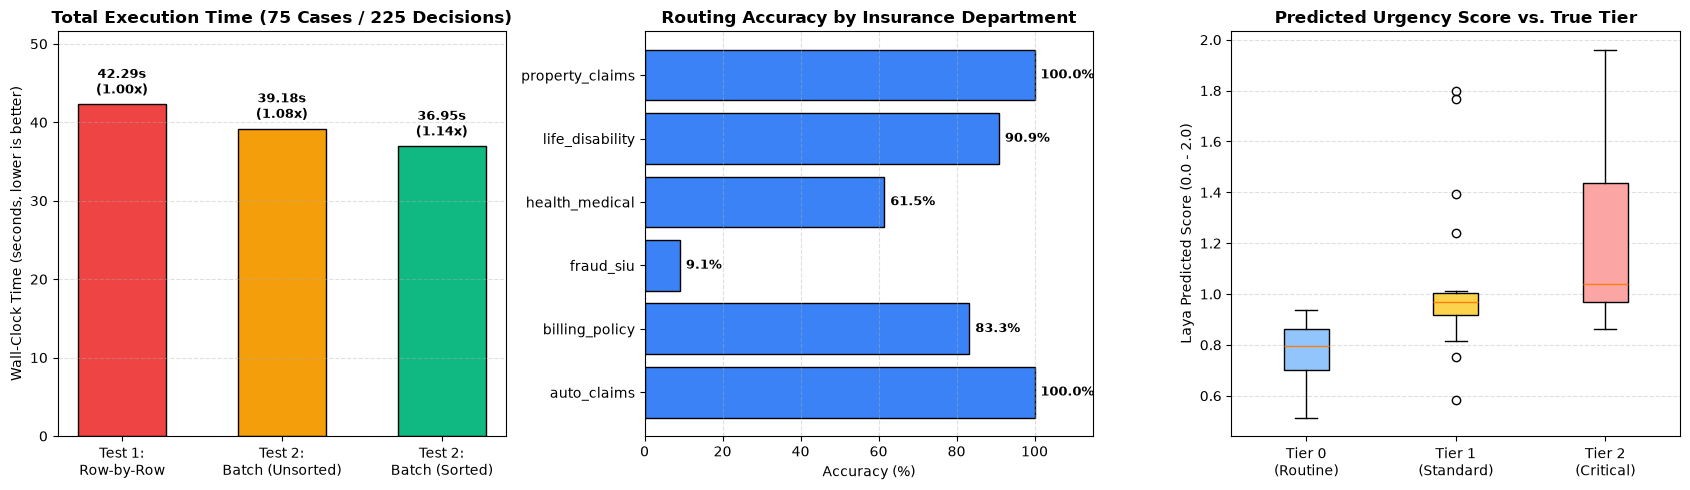

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Plot 1: Execution Time & Speedup (Row-by-Row vs Batch)
methods = ["Test 1:\nRow-by-Row", "Test 2:\nBatch (Unsorted)", "Test 2:\nBatch (Sorted)"]
times = [
    t_row_total,
    df_batch_bench.loc[df_batch_bench["Sort by Length"] == False, "Total Time (s)"].iloc[0],
    t_batch_total,
]
colors = ["#ef4444", "#f59e0b", "#10b981"]
bars = axes[0].bar(methods, times, color=colors, width=0.55, edgecolor="black")
axes[0].set_title("Total Execution Time (75 Cases / 225 Decisions)", fontweight="bold")
axes[0].set_ylabel("Wall-Clock Time (seconds, lower is better)")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)
for bar, t_val in zip(bars, times):
    speedup_str = f"{t_row_total / t_val:.2f}x"
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(times) * 0.02,
        f"{t_val:.2f}s\n({speedup_str})",
        ha="center", va="bottom", fontsize=9, fontweight="bold"
    )
axes[0].set_ylim(0, max(times) * 1.22)

# Plot 2: Accuracy by Insurance Department
dept_order = dept_summary.index.tolist()
acc_vals = dept_summary["accuracy_pct"].values
bars2 = axes[1].barh(dept_order, acc_vals, color="#3b82f6", edgecolor="black")
axes[1].set_title("Routing Accuracy by Insurance Department", fontweight="bold")
axes[1].set_xlabel("Accuracy (%)")
axes[1].set_xlim(0, 115)
axes[1].grid(axis="x", linestyle="--", alpha=0.4)
for bar, v in zip(bars2, acc_vals):
    axes[1].text(v + 1.5, bar.get_y() + bar.get_height() / 2, f"{v:.1f}%", va="center", fontsize=9, fontweight="bold")

# Plot 3: Predicted Urgency Score Distribution by Ground-Truth Tier
urg_groups = [
    df_eval.loc[df_eval["expected_urgency"] == lvl, "batch_urgency_score"].values
    for lvl in [0, 1, 2]
]
bp = axes[2].boxplot(urg_groups, tick_labels=["Tier 0\n(Routine)", "Tier 1\n(Standard)", "Tier 2\n(Critical)"], patch_artist=True)
for patch, c in zip(bp["boxes"], ["#93c5fd", "#fcd34d", "#fca5a5"]):
    patch.set_facecolor(c)
axes[2].set_title("Predicted Urgency Score vs. True Tier", fontweight="bold")
axes[2].set_ylabel("Laya Predicted Score (0.0 - 2.0)")
axes[2].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("data/benchmark_results.png", dpi=150, bbox_inches="tight")
plt.show()


## 9. Bonus: Multilingual Insurance Claim Routing with `laya.Router`
Laya's `Router` automatically detects scripts and languages in `< 0.5 ms` and routes English claims to `convaiinnovations/laya` (ModernBERT-large) and non-English claims to `convaiinnovations/laya/multilingual` (mmBERT-base, 100+ languages).

In [10]:
# Auto-extract multilingual model if needed
if not LOCAL_ML_DIR.exists() and PARTS_DIR.exists():
    print("Unpacking Multilingual model from models/laya_model_parts/...")
    try:
        import extract_model
        extract_model.extract_split_parts("laya_model_multilingual.zip.*", PARTS_DIR, LOCAL_ML_DIR)
    except Exception as e:
        print(f"Notice: Auto-extraction of multilingual skipped ({e}).")

router_models = {}
if LOCAL_EN_DIR.exists():
    router_models["english"] = str(LOCAL_EN_DIR)
if LOCAL_ML_DIR.exists():
    router_models["multilingual"] = str(LOCAL_ML_DIR)

if router_models:
    print(f"Initializing Router with local offline models: {list(router_models.keys())}")
    router = Router(models=router_models, default="english")
else:
    print("Initializing Router with Hugging Face Hub models...")
    router = Router(default="english")
    router.attach("english", agent)

multilingual_claims = [
    {"claimant": "Jean Dupont", "body": "Ma voiture a été percutée à un carrefour à Paris, le pare-chocs avant est détruit et j'ai besoin d'une dépanneuse."},
    {"claimant": "Hans Weber", "body": "Ein schwerer Sturm hat das Dach meines Hauses in München beschädigt. Wasser dringt in den zweiten Stock ein."},
    {"claimant": "Chen Wei", "body": "昨天在高速公路上发生追尾事故，我的车辆尾灯受损，对方全责。"},
    {"claimant": "Ahmad Razak", "body": "Kereta saya terlibat dalam kemalangan di Lebuhraya Persekutuan petang tadi. Bampar depan rosak teruk."},
]

router_results = []
for c in multilingual_claims:
    res = router.predict(
        c["body"],
        {
            "claim_type": {
                "type": "choice",
                "instructions": "Classify this insurance claim into one department.",
                "criteria": {
                    "auto_accident": "Vehicle collision, windshield damage, towing, fender bender",
                    "property_damage": "Roof leak, storm damage, flooding, pipe burst in home or building",
                    "health_injury": "Medical bill, hospitalization, doctor consultation",
                }
            }
        }
    )
    ans = res["answers"]["claim_type"]
    routing = res.get("routing", {})
    router_results.append({
        "Claimant": c["claimant"],
        "Detected Script": routing.get("detection", {}).get("script", "unknown"),
        "Routed Model": routing.get("model", "unknown"),
        "Predicted Department": ans["choice"],
        "Confidence": f"{ans['answer_confidence']:.1%}",
    })

df_router = pd.DataFrame(router_results)
display(df_router)

Claimant: Jean Dupont     | Routed Checkpoint: multilingual | Reason: Latin script but language looks like 'fr', not English
Claimant: Carlos Rivera   | Routed Checkpoint: multilingual | Reason: Latin script but language looks like 'es', not English
Claimant: Ananya Sharma   | Routed Checkpoint: multilingual | Reason: non-Latin script (devanagari, 79% of letters); the English checkpoint cannot read it
